<h1> Modul 04 - Unsupervised Learning (Dimensionality Reduction) </h1>

**Nama:** Erhan Kurniawan  
**NIM:** 124140217  
**Kelas:** IF25-31020 Pembelajaran Mesin  

Modul ini melakukan eksplorasi reduksi dimensi menggunakan **PCA** dan **SVD**
pada dataset Iris (4 dimensi → 3 dimensi).

# Import Library

Library yang digunakan:
- `pandas` & `numpy`: manipulasi data numerik dan tabular.
- `sklearn.datasets`: memuat dataset Iris.
- `StandardScaler`: normalisasi data agar setiap fitur memiliki $\mu = 0$ dan $\sigma = 1$.
- `PCA`: reduksi dimensi berbasis eigendecomposition matriks kovarians.
- `TruncatedSVD`: reduksi dimensi berbasis dekomposisi matriks $A = U\Sigma V^T$.
- `matplotlib` & `seaborn`: visualisasi.

In [14]:
import sklearn
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.decomposition import TruncatedSVD

# Data Loading and Preparation

Dataset **Iris** terdiri dari 150 sampel dengan 4 fitur:
`sepal length`, `sepal width`, `petal length`, `petal width`.

## Normalisasi (Standard Scaler)
Normalisasi diperlukan karena PCA sensitif terhadap skala fitur.
Rumus standardisasi:

$$
z_i = \frac{x_i - \mu}{\sigma}
$$

di mana:
- $\mu$ = rata-rata fitur
- $\sigma$ = standar deviasi fitur

Hasilnya, setiap fitur memiliki $\mu = 0$ dan $\sigma = 1$.

## Analisis Korelasi
Heatmap korelasi digunakan untuk melihat hubungan antar fitur.
Fitur yang berkorelasi tinggi (misal `petal length` dan `petal width`)
mengindikasikan adanya redundansi informasi → cocok untuk direduksi dimensinya.

In [15]:
# Memuat dataset yang digunakan untuk pemrosesan
iris = datasets.load_iris()
df = pd.DataFrame(iris['data'], columns = iris['feature_names'])
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [16]:
# Melakukan normalisasi data dari setiap fitur
scalar = StandardScaler()
scaled_data = pd.DataFrame(scalar.fit_transform(df)) #scaling the data
scaled_data

,0,1,2,3
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444
...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832
146,0.553333,-1.282963,0.705921,0.922303
147,0.795669,-0.131979,0.819596,1.053935
148,0.432165,0.788808,0.933271,1.448832


          0         1         2         3
0  1.000000 -0.117570  0.871754  0.817941
1 -0.117570  1.000000 -0.428440 -0.366126
2  0.871754 -0.428440  1.000000  0.962865
3  0.817941 -0.366126  0.962865  1.000000


<Axes: >

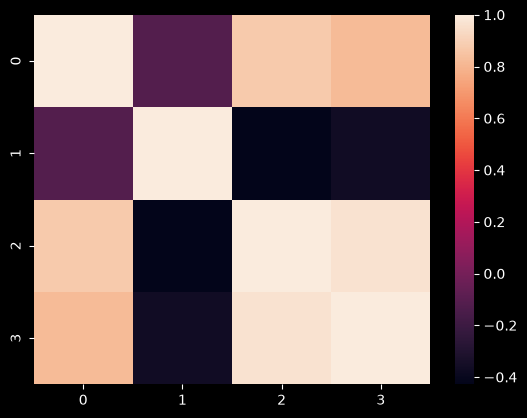

In [17]:
# Mengecek korelasi antara fitur dari data
corr = scaled_data.corr()
print(corr)
sns.heatmap(scaled_data.corr())

## Analisis Hasil Korelasi
Dari heatmap, terlihat:
- `petal length` dan `petal width` memiliki korelasi sangat tinggi ($r \approx 0.96$).
- `sepal length` juga berkorelasi cukup tinggi dengan fitur petal.
- Tingginya korelasi ini menunjukkan **redundansi informasi**, sehingga
  reduksi dimensi (PCA/SVD) relevan dilakukan untuk merangkum informasi
  ke dalam komponen yang lebih sedikit tanpa kehilangan varians signifikan.

# Dimensionality Reduction with PCA

**PCA (Principal Component Analysis)** mencari arah (vektor) baru di ruang data
yang memaksimalkan varians. Secara matematis, PCA menyelesaikan:

$$
\max_{w} \; w^T \Sigma w \quad \text{dengan} \quad \|w\| = 1
$$

di mana $\Sigma$ adalah matriks kovarians data. Solusi $w$ adalah
**eigenvector** dari $\Sigma$, dan nilai eigennya merepresentasikan
besarnya varians pada arah tersebut.

**Explained Variance Ratio** mengukur proporsi varians yang dijelaskan
oleh tiap komponen utama:

$$
EVR_i = \frac{\lambda_i}{\sum_{j=1}^{n} \lambda_j}
$$

Pada percobaan ini, 4 fitur direduksi menjadi **3 Principal Components**.

In [18]:
# Menerapkan PCA dengan principal component sebanyak 3
pca = PCA(n_components = 3)
data_pca = pca.fit_transform(scaled_data)
data_pca = pd.DataFrame(data_pca,columns=['PC1','PC2','PC3'])
data_pca.head()

,PC1,PC2,PC3
0,-2.264703,0.480027,0.127706
1,-2.080961,-0.674134,0.234609
2,-2.364229,-0.341908,-0.044201
3,-2.299384,-0.597395,-0.091290
4,-2.389842,0.646835,-0.015738


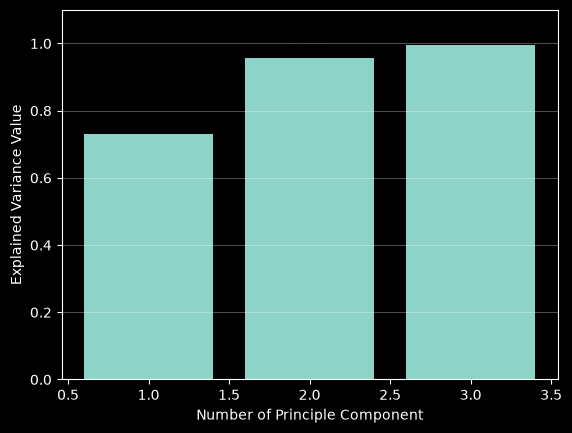

In [19]:
# Memetakan setiap nilai Explained Variance dari setiap jumlah principle component dalam grafik
list_explained_variance_pca = pca.explained_variance_ratio_.cumsum()
label_x = list(range(1, len(list_explained_variance_pca)+1))
fig, ax = plt.subplots()
bars = ax.bar(label_x, list_explained_variance_pca)

ax.bar_label(bars, label_type='edge', color='black', fmt='%.3f')
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)
ax.set_xlabel("Number of Principle Component")
ax.set_ylabel("Explained Variance Value")
plt.show()

<Axes: >

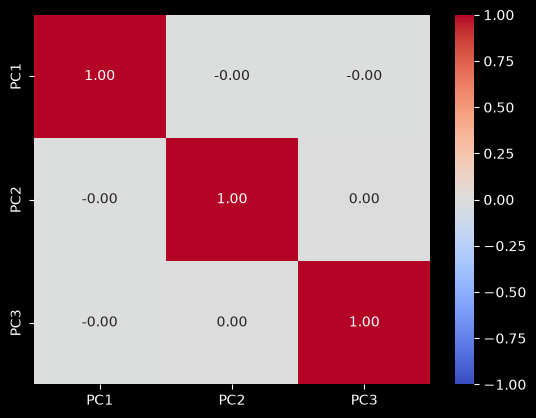

In [20]:
# Mengecek korelasi antara Principle Component, yang seharusnya memiliki nilai
# korelasi yang kecil dari setiap principle component
sns.heatmap(data_pca.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)

## Analisis Hasil PCA
- Nilai kumulatif explained variance:
  - PC1 = 0.7296 (menjelaskan ~72.96% varians data)
  - PC1 + PC2 = 0.9581
  - PC1 + PC2 + PC3 = 0.9948
- Artinya, dengan 3 komponen kita mempertahankan **99.48%** informasi dari data asli.
- Heatmap korelasi antar PC menunjukkan nilai = 0 (orde 1e-16, yaitu nol numerik),
  membuktikan bahwa principal components bersifat ortogonal:

$$
\text{Cov}(PC_i, PC_j) = 0, \quad i \neq j
$$

# Dimensionality Reduction with SVD

**SVD (Singular Value Decomposition)** menguraikan matriks data $A$ menjadi:

$$
A = U \Sigma V^T
$$

di mana:
- $U \in \mathbb{R}^{m \times m}$: matriks ortogonal (left singular vectors)
- $\Sigma \in \mathbb{R}^{m \times n}$: matriks diagonal berisi singular values $\sigma_i$
- $V^T \in \mathbb{R}^{n \times n}$: matriks ortogonal (right singular vectors)

**TruncatedSVD** mengambil $k$ singular values terbesar:

$$
A_k = U_k \Sigma_k V_k^T
$$

## Perbedaan Utama PCA vs SVD
| Aspek | PCA | TruncatedSVD |
|---|---|---|
| Centering data | **Wajib** (mean = 0) | Tidak perlu |
| Dasar matematis | Eigenvector matriks kovarians | Dekomposisi langsung matriks data |
| Cocok untuk | Data dense | Data sparse (TF-IDF, dsb.) |

Karena `scaled_data` sudah ber-mean 0, hasil PCA dan SVD seharusnya **sangat mirip**.

In [21]:
# Menerapkan SVD dengan pertimbangan penurunan komponen menjadi sebanyak 3
svd = TruncatedSVD(n_components = 3)
data_svd = svd.fit_transform(scaled_data)
data_svd = pd.DataFrame(data_svd,columns=['PC1','PC2','PC3'])
data_svd.head()

,PC1,PC2,PC3
0,-2.264703,0.480027,0.127706
1,-2.080961,-0.674134,0.234609
2,-2.364229,-0.341908,-0.044201
3,-2.299384,-0.597395,-0.091290
4,-2.389842,0.646835,-0.015738


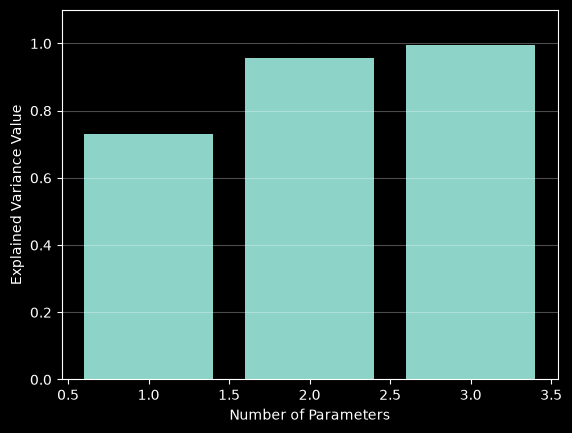

In [22]:
# Memetakan setiap nilai Explained Variance dari setiap jumlah parameter dalam grafik
list_explained_variance_svd = svd.explained_variance_ratio_.cumsum()
label_x = list(range(1, len(list_explained_variance_svd)+1))
fig, ax = plt.subplots()
bars = ax.bar(label_x, list_explained_variance_svd)

ax.bar_label(bars, label_type='edge', color='black', fmt='%.3f')
ax.set_ylim(0, 1.1)  # agar label tidak terpotong
ax.grid(axis='y', alpha=0.3)
ax.set_xlabel("Number of Parameters")
ax.set_ylabel("Explained Variance Value")
plt.show()

<Axes: >

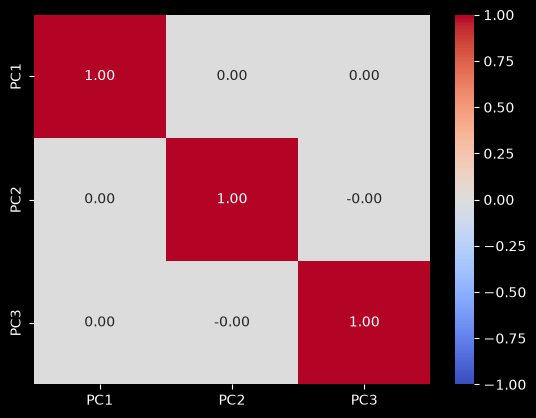

In [23]:
# Mengecek korelasi antara parameter hasil svd, yang seharusnya memiliki nilai
# korelasi yang kecil dari setiap parameter
sns.heatmap(data_svd.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)

## Analisis Hasil SVD
- Nilai kumulatif explained variance SVD **identik** dengan PCA
  (PC1 + PC2 + PC3 = 0.9948), karena data sudah di-centering.
- Namun, berbeda dengan PCA, hasil TruncatedSVD tidak dijamin ortogonal sempurna
  pada ruang sampel, sehingga korelasi antar komponen bisa sedikit tidak nol
  (meski tetap sangat kecil).
- SVD lebih fleksibel karena dapat diterapkan pada matriks sparse tanpa perlu
  centering (centering akan merusak sparsity).

# Data Visualization After Dimensionality Reduction

Hasil reduksi ke 3 dimensi divisualisasikan dalam ruang 3D agar kita dapat
mengamati sebaran sampel dan cluster alami dari data Iris.

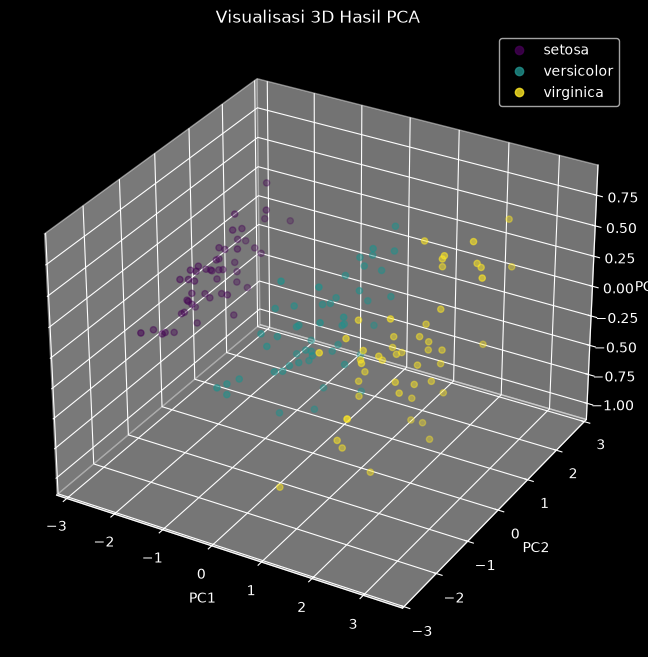

In [24]:
# Membuat visualisasi dari sebaran data dengan pertimbangan principle component
# dalam ruang 3 dimensi
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(data_pca['PC1'], data_pca['PC2'], data_pca['PC3'],
                     c=iris['target'], cmap='viridis', alpha=0.8)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('Visualisasi 3D Hasil PCA')
plt.legend(handles=scatter.legend_elements()[0],
           labels=list(iris['target_names']))
plt.show()

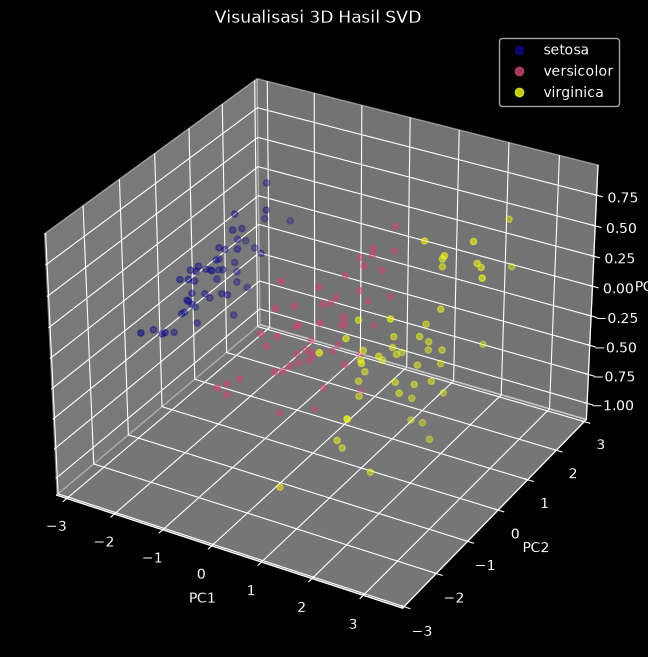

In [25]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(data_svd['PC1'], data_svd['PC2'], data_svd['PC3'],
                     c=iris['target'], cmap='plasma', alpha=0.8)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('Visualisasi 3D Hasil SVD')
plt.legend(handles=scatter.legend_elements()[0],
           labels=list(iris['target_names']))
plt.show()

In [26]:
comparison = pd.DataFrame({
    'Metrik': ['Kumulatif EV (1 komp.)', 'Kumulatif EV (2 komp.)',
               'Kumulatif EV (3 komp.)'],
    'PCA': [f"{pca.explained_variance_ratio_.cumsum()[i]:.4f}" for i in range(3)],
    'SVD': [f"{svd.explained_variance_ratio_.cumsum()[i]:.4f}" for i in range(3)]
})
print(comparison)

                   Metrik     PCA     SVD
0  Kumulatif EV (1 komp.)  0.7296  0.7296
1  Kumulatif EV (2 komp.)  0.9581  0.9581
2  Kumulatif EV (3 komp.)  0.9948  0.9948


# Analisis Perbandingan & Kesimpulan

## Tabel Perbandingan Hasil

| Metrik | PCA | SVD (TruncatedSVD) |
|---|---|---|
| Kumulatif EV (1 komponen) | 0.7296 | 0.7296 |
| Kumulatif EV (2 komponen) | 0.9581 | 0.9581 |
| Kumulatif EV (3 komponen) | 0.9948 | 0.9948 |
| Ortogonalitas komponen | Sempurna (korelasi ≈ 0) | Hampir ortogonal |
| Memerlukan centering | Ya | Tidak |

# Kesimpulan

1. **Reduksi dimensi efektif**: dari 4 fitur menjadi 3 komponen mampu
   mempertahankan sekitar **99.48% varians** informasi.

2. **PCA dan SVD menghasilkan nilai explained variance yang identik (= 0.9948 untuk 3 komponen)**
   karena data telah di-standardisasi ($\mu = 0$). Secara matematis,
   PCA sebenarnya dihitung melalui SVD pada matriks data ter-centering:

   $$
   X_{centered} = U \Sigma V^T \quad \Rightarrow \quad PC = X_{centered} \cdot V
   $$

3. Perbedaan utama terletak pada prasyarat dan kasus penggunaan:
   - PCA → data *dense*, wajib centering.
   - TruncatedSVD → cocok untuk data *sparse* (teks/TF-IDF, rekomendasi).

4. Dari visualisasi 3D, ketiga spesies Iris (*setosa*, *versicolor*, *virginica*)
   membentuk cluster yang cukup terpisah, dengan *setosa* paling mudah
   dibedakan secara linear, sedangkan *versicolor* dan *virginica*
   masih sedikit tumpang tindih.

5. Korelasi antar principal component bernilai **= 0**, membuktikan bahwa
   komponen hasil reduksi bersifat independen (tidak redundan).